# AllRecipes Data Analysis Project

## Imports

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Introduction

The data for this project comes from Allrecipes, a popular online platform where home cooks and food enthusiasts share and review recipes from around the world (Allrecipes, n.d.). The project comprises two datasets: allrecipes, a general collection of roughly 14,000 recipes spanning a wide range of dish types, cuisines, and a smaller collection of around 2,200 recipes organised by country of origin. For each recipe, the dataset captures a rich set of attributes, including the list of ingredients, nutritional information per serving (calories, fat, carbohydrates, and protein), the time needed to prepare and cook the dish, user ratings, and the number of reviews received (Mubia, 2025). One limitation to note is that review counts for highly popular recipes are truncated at the thousands, so these figures should be treated as approximate for widely-reviewed dishes (Mubia, 2025).

With such a large and varied collection of recipes, a practical question emerges: which recipes are genuinely worth attempting? A dish might earn glowing reviews yet require several hours of work, while another might be quick to make but fail to impress. This project explores the concept of "actionable" recipes, which refer to those that sit at the sweet spot of being both highly rated by users and achievable within a short amount of time. Namely, our question of interest is: Which recipes are the most "actionable" — high rating with low total time? To investigate this, we primarily draw on the general allrecipes dataset, as its substantially larger sample provides a more reliable basis for identifying meaningful patterns. **[TO BE UPDATED: The variables most relevant to this analysis are the average user rating out of five stars (avg_rating) and the total time recorded for each recipe in minutes (total_time), which includes preparation and cooking time but excludes passive waiting periods such as refrigeration, marination, and additional wait times due to inconsistent availability across recipes. We additionally use the number of ratings received (total_ratings) to ensure recipes have sufficient community feedback to be considered reliable, and the recipe name (name) to derive broad recipe categories through keyword extraction.]** By examining how these variables interact across thousands of recipes, we aim to surface patterns that reflect not just what tastes good, but what is realistically appealing for everyday cooking.

## 2. Initial Data Cleaning and Summary

### 2.1 Loading the datasets

In [2]:
url_recipes = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-09-16/all_recipes.csv'
url_cuisines = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-09-16/cuisines.csv'

# Turn links into DataFrames
df_recipes = pd.read_csv(url_recipes)
df_cuisines = pd.read_csv(url_cuisines)

In [3]:
df_recipes.head()

,name,url,author,date_published,ingredients,calories,fat,carbs,protein,avg_rating,total_ratings,reviews,prep_time,cook_time,total_time,servings
0,Chewy Whole Wheat Peanut Butter Brownies,https://www.allrecipes.com/recipe/140717/chewy...,DMOMMY,2020-06-18,"⅓ cup margarine, softened, ⅔ cup white sugar, ...",222.0,13.0,24.0,6.0,4.4,47.0,36.0,20,35,55,16.0
1,Pumpkin Pie Eggnog,https://www.allrecipes.com/recipe/269204/pumpk...,Bobbie Susan,2022-09-26,"12 egg yolks, 2 cups heavy whipping cream, ½ ...",477.0,31.0,43.0,8.0,5.0,1.0,1.0,10,5,495,8.0
2,Eggs Poached in Tomato Sauce,https://www.allrecipes.com/recipe/238054/eggs-...,Bren,2018-06-08,"2 tablespoons olive oil, or to taste, ½ onion...",354.0,18.0,32.0,20.0,4.8,4.0,4.0,10,75,85,4.0
3,Minestrone Casserole,https://www.allrecipes.com/minestrone-casserol...,Sarah Brekke,2025-03-03,4 cups dried mafalda pasta (mini lasagna noodl...,356.0,9.0,53.0,19.0,4.3,14.0,13.0,20,40,60,8.0
4,Yummy Stuffed Peppers,https://www.allrecipes.com/recipe/241937/yummy...,Procrastigirl,2024-12-11,"4 green bell peppers, halved lengthwise and se...",366.0,22.0,23.0,19.0,4.7,84.0,67.0,30,95,125,8.0


In [4]:
df_cuisines.head()

,name,country,url,author,date_published,ingredients,calories,fat,carbs,protein,avg_rating,total_ratings,reviews,prep_time,cook_time,total_time,servings
0,Saganaki (Flaming Greek Cheese),Greek,https://www.allrecipes.com/recipe/263750/flami...,John Mitzewich,2024-02-07,"1 (4 ounce) package kasseri cheese, 1 tablespo...",391.0,25.0,15.0,16.0,4.8,25.0,22.0,10,5,15,2.0
1,Coney Island Knishes,Jewish,https://www.allrecipes.com/recipe/272334/coney...,John Mitzewich,2024-11-26,"2 ¾ cups all-purpose flour, or more as needed,...",301.0,17.0,31.0,7.0,4.6,10.0,9.0,30,75,180,16.0
2,Diana's Hawaiian Bread Rolls,Australian and New Zealander,https://www.allrecipes.com/recipe/22797/dianas...,CHIPPENDALE,2022-07-14,1 ½ cups warm water (110 degrees F/45 degrees ...,64.0,3.0,9.0,1.0,4.3,126.0,104.0,20,15,180,12.0
3,Chilean Pebre,Chilean,https://www.allrecipes.com/recipe/273763/chile...,Heidi,2025-01-31,"½ cup chopped cilantro, ¼ cup olive oil, ¼ cup...",106.0,9.0,7.0,1.0,5.0,1.0,1.0,10,0,10,6.0
4,Tex-Mex Sheet Cake,Tex-Mex,https://www.allrecipes.com/recipe/22388/tex-me...,Ann,2025-02-18,"2 cups all-purpose flour, 1 ½ cups brown sugar...",449.0,23.0,58.0,7.0,3.8,13.0,11.0,30,15,45,15.0


### 2.2 Data cleaning

In [5]:
# Use outer join to merge cuisine labels onto recipes
df = pd.merge(df_recipes, 
              df_cuisines[['url', 'country']].rename(columns={'country': 'cuisine'}), 
              on='url', 
              how='outer')

# Standardize column types to numeric
num_cols = ["calories", "fat", "carbs", "protein", "avg_rating", 
            "total_ratings", "reviews", "prep_time", "cook_time", 
            "total_time", "servings"]

for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Drop rows missing essential metrics
df.dropna(subset=['name', 'avg_rating', 'ingredients', 'prep_time', 
                  'cook_time', 'total_time'], inplace=True)

# Remove recipes with 0 time
df = df[df['total_time'] > 0]

Other than empty ratings, time and ingredients using NA, some values in the 'author' column are 'Allrecipes Member' which may be the NA values of authors' names but there is no need to remove those recipes as we are not concerned with the authors of the recipes.

### 2.3 Some feature engineering for summary statistics

In [6]:
# Count ingredient lines
def count_ingredients(s):
    if pd.isna(s) or str(s).strip() == "":
        return 0
    
    # Cleaning Noise (Units, preparation steps and common adjectives)
    noise_list = ["cup", "cups", "tablespoon", "tablespoons", "teaspoon", "teaspoons", 
        "pound", "pounds", "ounce", "ounces", "gram", "grams", "ml", "beaten", "divided", "fresh"
        "chopped", "minced", "sliced", "diced", "crushed", "mashed", "clove", "cloves", "pinch", "ripe"
        "dried", "fresh", "to", "taste", "as", "needed", "large", "small", "medium", "all-purpose", 
        "packed", "shredded", "optional", "more", "less", "than", "or", 'can', 'packaged'
    ]
    
    # Split by comma (line separation)
    raw_lines = str(s).split(",")
    distinct_ingredients = set()
    
    for line in raw_lines:
        clean = line.lower()                                            # lowercase

        clean = "".join([char for char in clean if not char.isdigit()]) # Remove numbers

        for char in ".,()!":                                            # Replace punctuation with spaces 
            clean = clean.replace(char, " ")

        words = clean.split()                                           # Remove noise words
        filtered_words = [word for word in words if word not in noise_list]
        clean_name = " ".join(filtered_words).strip()
        
        # Only add if there is meaningful text left (ignores words like "a" and "or" or empty strings)
        if len(clean_name) > 2:
            distinct_ingredients.add(clean_name)
            
    return len(distinct_ingredients)

df['n_ingredient_lines'] = df['ingredients'].apply(count_ingredients)

In [7]:
# Nutritional value of recipe using the nutrient density
# Nutrient Density is the number of nutrients in a food relative to the calories that food provides.
# Multiply protein and fat to their energy density, 4 and 9, and divide my the calories to get the nutrient density
# [(protein x 4 + fat x 9)/calories]
df['nutrient_density'] = ((df['protein'] * 4) + (df['fat'] * 9)) / df['calories']

# Find nutrient density per serving
df['nutrient_density_per_serving'] = df['nutrient_density'] / df['servings']

In [8]:
df['log_total_time'] = np.log1p(df['total_time']) # log-transform heavily skewed data
df_filtered = df[df['total_ratings'] >= 10].copy() # Filter for reliable averages

# Actionable Score
df_filtered['z_rating'] = stats.zscore(df_filtered['avg_rating'])

df_filtered['z_ingredients'] = stats.zscore(df_filtered['n_ingredient_lines'])
df_filtered['complexity_score'] = df_filtered['z_rating'] - df_filtered['z_ingredients']

df_filtered['z_log_time'] = stats.zscore(np.log1p(df_filtered['total_time']))
df_filtered['action_score'] = df_filtered['z_rating'] - df_filtered['z_log_time']

df_filtered['ultimate_score'] = df_filtered['z_rating'] - (df_filtered['z_log_time'] + df_filtered['z_ingredients'])

In [9]:
df_filtered.columns

Index(['name', 'url', 'author', 'date_published', 'ingredients', 'calories',
       'fat', 'carbs', 'protein', 'avg_rating', 'total_ratings', 'reviews',
       'prep_time', 'cook_time', 'total_time', 'servings', 'cuisine',
       'n_ingredient_lines', 'nutrient_density',
       'nutrient_density_per_serving', 'log_total_time', 'z_rating',
       'z_ingredients', 'complexity_score', 'z_log_time', 'action_score',
       'ultimate_score'],
      dtype='object')

### 2.4 Key summary statistics

#### Individual data statistics

In [10]:
print("--- General Dataset Shape ---")
print(f"Total recipes after cleaning: {len(df):,}")
print(f"Recipes with cuisine tags: {df['cuisine'].notna().sum():,}")

print("\n" + "="*100)

print("\n--- Key Factors Summary ---")
rating_stats = df[['avg_rating', 'total_ratings', 'total_time', 'nutrient_density_per_serving', 'servings', 'n_ingredient_lines']].describe().loc[['min', '25%', 'mean', '50%', '75%', 'max']]
display(rating_stats)

--- General Dataset Shape ---
Total recipes after cleaning: 13,104
Recipes with cuisine tags: 1,001


--- Key Factors Summary ---


,avg_rating,total_ratings,total_time,nutrient_density_per_serving,servings,n_ingredient_lines
min,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000
25%,4.400000,5.000000,30.000000,0.039969,4.250000,8.000000
mean,4.531219,102.082036,149.599435,0.102260,11.058729,11.123932
50%,4.600000,26.000000,55.000000,0.077519,8.000000,10.000000
75%,4.800000,111.000000,105.000000,0.131356,12.000000,14.000000
max,5.000000,997.000000,60485.000000,1.000000,300.000000,38.000000


Insights about the data is that the mean (4.53) and median (4.60) for avg_ratings are very high and close to each other. This suggests that the data is **heavily left skewed** and has a large positivity bias for ratings. On Allrecipes, a 4.0 rating is not actually good comparatively, but it is actually below average. Hence, this statistic shows that the bar for a good rating is actually very high and that the most actionable recipes should only contain recipes that are above the median (4.60). 

Moreover, there is a large difference between mean (102) and median (26) for total_ratings as there are many ratings (max=997) that are pulling the average up. This suggests that the data for total ratings is **largely right skewed**. Hence, **recipes with less than 10 reviews are filtered out** to ensure that the actionable recipes found are **reliable** and not just based on one review. This ensures that the **actionable recipes found are not only fast, have high ratings and a low number of ingredients, but they are also reliable** with at least more than 10 number of reviews.

Additionally, there is also a large difference between mean (150) and median (55) for total_time. Similar to total_ratings, the data for total_time is also **heavily right skewed**. Hence, a **log_total_time** column is made for a more meaningful visualisation.

In [11]:
print(df_filtered['servings'].value_counts())

servings
8.0      1697
6.0      1518
4.0      1454
12.0      986
10.0      450
         ... 
26.0        1
134.0       1
27.0        1
22.0        1
49.0        1
Name: count, Length: 63, dtype: int64


The most common serving sizes are 4, 6, 8, and 12, which are all typical home cooking portions. Beyond that, counts drop off sharply, for instance values like 26, 27, 49, 134 each appear only once. 

Based on this, would create serving_group
* Small: 1–4 servings (individual/couple meals)
* Medium: 5–8 servings (family-sized meals)
* Large: 9+ servings (batch cooking/gatherings)

#### Interconnected data statistics

In [12]:
# Do faster recipes get more reviews?
print("\n--- Total Reviews by Time Category ---")
df['time_quartile'] = pd.qcut(df['total_time'], 4, labels=['Very Fast', 'Fast', 'Medium', 'Slow'])
engagement = df.groupby('time_quartile', observed=True)['total_ratings'].agg(['mean', 'std'])
display(engagement)


--- Total Reviews by Time Category ---


,mean,std
time_quartile,,
Very Fast,100.252870,172.070778
Fast,103.902074,176.484700
Medium,110.125816,181.118917
Slow,93.493643,162.234260


Another interesting insight is that the time category with the **highest mean total ratings** (110) is the **medium or third quartile** of the total time for all the recipes, while the **slow category or the last quartile** has the **lowest** (93). This suggests that **time is a real factor** that affects the user's decision on which recipe to follow. A medium time is preferred by the community as seen by the mean total reviews which may mean that the most actionable recipes determined by current readers are those that take medium time, followed by fast, very fast and slow time. This validates our guiding question as it shows that the total time taken for a recipe plays a role in the willingness of users to follow the recipe. 

In [13]:
# Is there a correlation between Time and Rating?
corr_time_rating = df_filtered[['total_time', 'avg_rating']].corr().iloc[0,1]
print(f"\nPearson Correlation between Total Time and Average Rating: {corr_time_rating:.4f}")

# What are the fastest recipes with high ratings?
print("\n--- Top 5 Fastest High-Rated Recipes (High Rating, Low Time) ---")
display(df_filtered.sort_values('action_score', ascending=False)[['name', 'total_time', 'avg_rating', 'n_ingredient_lines', 'action_score']].head(5))

print("\n" + "="*100)

# Is there a correlation between Number of Ingredients and Rating?
corr_ingredients_rating = df_filtered[['n_ingredient_lines', 'avg_rating']].corr().iloc[0,1]
print(f"\nPearson Correlation between Number of Ingredients and Average Rating: {corr_ingredients_rating:.4f}")

# What are the low-ingredient recipes with high ratings?
print("\n--- Top 5: Simplest High-Rated Recipes (Low Ingredients) ---")
display(df_filtered.sort_values('complexity_score', ascending=False)
        [['name', 'avg_rating', 'n_ingredient_lines', 'complexity_score']].head(5))

print("\n" + "="*100)

# Is there a correlation between Time and Number of Ingredients?
complexity_corr = df_filtered[['total_time', 'n_ingredient_lines']].corr().iloc[0,1]
print(f"\nCorrelation between Total Time and Number of Ingredients: {complexity_corr:.4f}")

# What are the fastest, low-ingredient recipes with high ratings?
print("\n--- Top 5: Simplest and Fastest High-Rated Recipes (High Rating, Low Time, Low Ingredients) ---")
display(df_filtered.sort_values('ultimate_score', ascending=False)
        [['name', 'avg_rating', 'total_time', 'n_ingredient_lines', 'ultimate_score']].head(5))


Pearson Correlation between Total Time and Average Rating: 0.0058

--- Top 5 Fastest High-Rated Recipes (High Rating, Low Time) ---


,name,total_time,avg_rating,n_ingredient_lines,action_score
8077,Christmas Poinsettia Punch,5.0,5.0,6,4.022274
1761,Peach Cosmo,5.0,5.0,5,4.022274
7213,Prickly Pear Margarita,5.0,5.0,6,4.022274
2227,Simple Cranberry Spinach Salad,5.0,5.0,5,4.022274
4417,Pumpkin Pie Spice I,1.0,4.7,4,3.979555




Pearson Correlation between Number of Ingredients and Average Rating: 0.0973

--- Top 5: Simplest High-Rated Recipes (Low Ingredients) ---


,name,avg_rating,n_ingredient_lines,complexity_score
10041,Baked Corn Tortilla Strips for Mexican Soups,5.0,2,3.654063
12139,Microwave Spaghetti Squash,5.0,2,3.654063
9867,Low-Carb Keto Cheese Taco Shells,4.9,1,3.504139
9514,Homemade Clotted Cream,4.9,1,3.504139
11253,3-Ingredient Whipped Cream,5.0,3,3.432800




Correlation between Total Time and Number of Ingredients: -0.0086

--- Top 5: Simplest and Fastest High-Rated Recipes (High Rating, Low Time, Low Ingredients) ---


,name,avg_rating,total_time,n_ingredient_lines,ultimate_score
14909,Classic White Wine Spritzer,4.9,5.0,2,5.589619
4417,Pumpkin Pie Spice I,4.7,1.0,4,5.475561
5753,S'mores,4.9,5.0,3,5.368356
8445,Colored Sugar,4.9,5.0,3,5.368356
5676,Classic Ham Glaze,4.9,5.0,3,5.368356


In investigating the relationship between rating with time and number of ingredients, there is **lack of correlation** between time, ingredients and ratings (r = 0.0058 between time and rating, r = 0.1028 between ingredients and rating, and r = -0.0091 between ingredients and time). This shows that there is no correlation between ratings with time and with ingredients, making the search for actionable recipes valid. 

The most actionable recipe based on time and both time and number of ingredients are **drinks** and the top 5 actionable recipes is found to contain many drinks. However, the most actionable recipe based on the number of ingredients is food and the top 5 contains mainly food, soup and creams. This suggests that for high ratings, the types of recipes for lowest time and lowest number of ingredients differ slightly. However, the most actionable recipes are often **components (creams) or drinks**. This suggests that recipes that take less time are more likely recipes for drinks. This validates our finding that recipes with medium time have the highest mean total reviews as the medium time category may have more recipes for food that take less time. Hence, current users may be more attracted to these recipes.

#### Initial findings for actionable recipes

In [14]:
# Define actionable recipes as as the top 10% of ultimate_score
top_threshold = df_filtered['ultimate_score'].quantile(0.9)
df_filtered['is_top_actionable'] = df_filtered['ultimate_score'] >= top_threshold

print("\n" + "="*100)

# Do actionable recipes have higher nutritional value(nutrient_density_per_serving))?
print("\n--- Nutritional Comparison: Actionable vs. Others ---")
nutritional_comp = df_filtered.groupby('is_top_actionable')[['nutrient_density_per_serving']].median()
display(nutritional_comp)



--- Nutritional Comparison: Actionable vs. Others ---


,nutrient_density_per_serving
is_top_actionable,
False,0.075300
True,0.091116


The fact that actionable recipes has a **higher nutrient_density_per_serving** is a key insight. It suggests that actionable recipes are **fast, lighter and potentially healthier**. However, this may also be due to the fact that the most actionable recipes are mostly drinks that would usually have less calories, fat and protein compared to food. 

## 3. Visualisation

### 3.1 Scatter plot

This plot uses three variables: total cooking time in minutes (`total_time`), average user rating out of five stars (`avg_rating`), and number of servings (`servings`), which is binned into three groups — small (1–4 servings), medium (5–8 servings), and large (9+ servings) (`serving_group`). Each point in the scatter plot represents an individual recipe.

A scatter plot is ideal here because our core question asks about the relationship between two continuous variables, time and rating, and a scatter plot is the most direct way to visualise how these two dimensions interact across thousands of recipes simultaneously. It allows the reader to immediately identify where the actionable zone lies: recipes that cluster in the upper-left region of the plot (low total time, high rating) are the most actionable. Quadrant lines can be drawn to make this zone explicit.

Faceting by serving size adds a meaningful third dimension without cluttering a single plot. It allows us to investigate whether the actionable zone shifts depending on the scale of the recipe. For instance, whether large-batch recipes tend to require more time and thus are less likely to be actionable, or whether smaller single-serving recipes dominate the sweet spot. The bins were determined based on the observed distribution of serving sizes in the data. This faceted design keeps each individual panel clean and readable while enabling direct visual comparison across serving size groups.

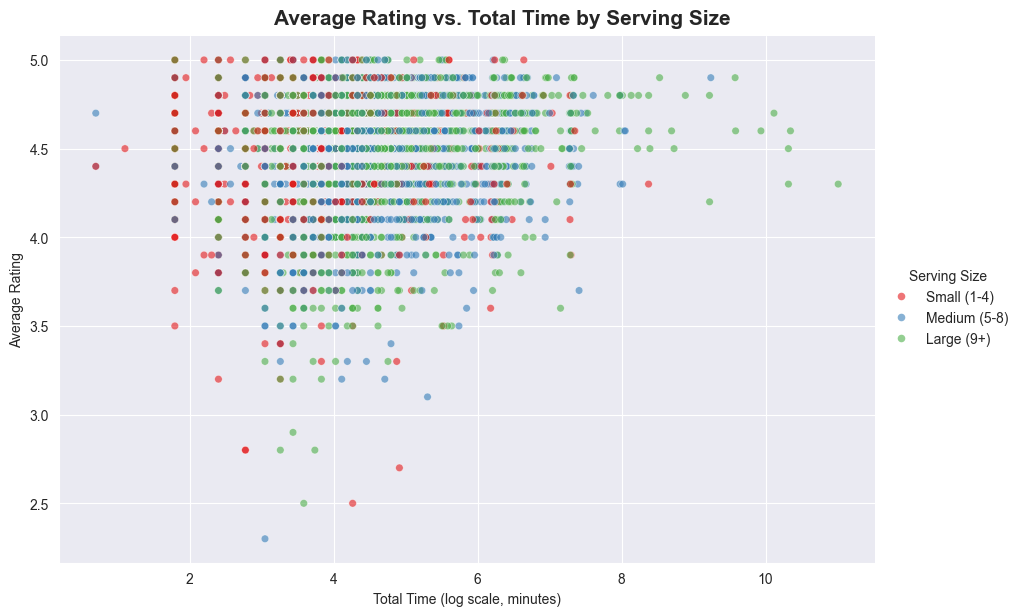

In [15]:
# Define serving group bins
serving_bins = [0, 4, 8, np.inf]
serving_labels = ['Small (1-4)', 'Medium (5-8)', 'Large (9+)']
df_filtered['serving_group'] = pd.cut(df_filtered['servings'], bins=serving_bins, labels=serving_labels)

sns.set_style('darkgrid')

# Plot the Scatterplot
g = sns.relplot(
    data=df_filtered,
    kind='scatter',
    x='log_total_time',
    y='avg_rating',
    hue='serving_group',
    hue_order=['Small (1-4)', 'Medium (5-8)', 'Large (9+)'],
    palette='Set1',
    alpha=0.6,
    s=30,
    height=6,
    aspect=1.5
)

g.set_axis_labels('Total Time (log scale, minutes)', 'Average Rating')
g.figure.suptitle('Average Rating vs. Total Time by Serving Size', 
                   fontsize=15, fontweight='bold', y=1.02)
g.legend.set_title('Serving Size')

plt.show()

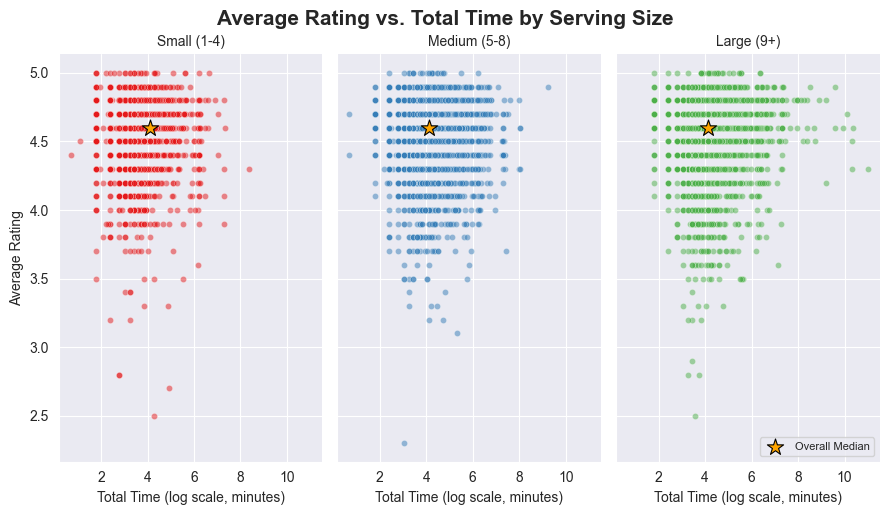

In [16]:
# Define serving group bins
serving_bins = [0, 4, 8, np.inf]
serving_labels = ['Small (1-4)', 'Medium (5-8)', 'Large (9+)']
df_filtered['serving_group'] = pd.cut(df_filtered['servings'], bins=serving_bins, labels=serving_labels)

# Set style and extract Set1 colours
sns.set_style('darkgrid')
panel_colours = sns.color_palette('Set1', 3)

# Overall median reference point
median_time = df_filtered['log_total_time'].median()
median_rating = df_filtered['avg_rating'].median()

# Plot the Scatterplot
g = sns.relplot(
    data=df_filtered,
    kind='scatter',
    x='log_total_time',
    y='avg_rating',
    col='serving_group',
    alpha=0.5,
    s=20,
    height=5,
    aspect=0.6,
    legend=False
)

# Add overall median marker to each panel and set uniform colour per panel
for ax, colour in zip(g.axes.flat, panel_colours):
    ax.collections[0].set_facecolor(colour)
    ax.scatter(median_time, median_rating,
               color='orange', s=150, zorder=5,
               edgecolors='black', linewidth=0.8,
               marker='*', label='Overall Median')

# Add legend for the median marker only
g.axes.flat[-1].legend(loc='lower right', fontsize=8)
g.set_axis_labels('Total Time (log scale, minutes)', 'Average Rating')
g.set_titles(col_template='{col_name}')
g.figure.suptitle('Average Rating vs. Total Time by Serving Size',
                   fontsize=15, fontweight='bold', y=1.02)

plt.show()

### 3.3 Heatmap

/var/folders/94/fmmpbfl512769dp5lmxfqjh40000gn/T/ipykernel_33446/3970174979.py:10: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  heatmap_data = df_filtered.pivot_table(


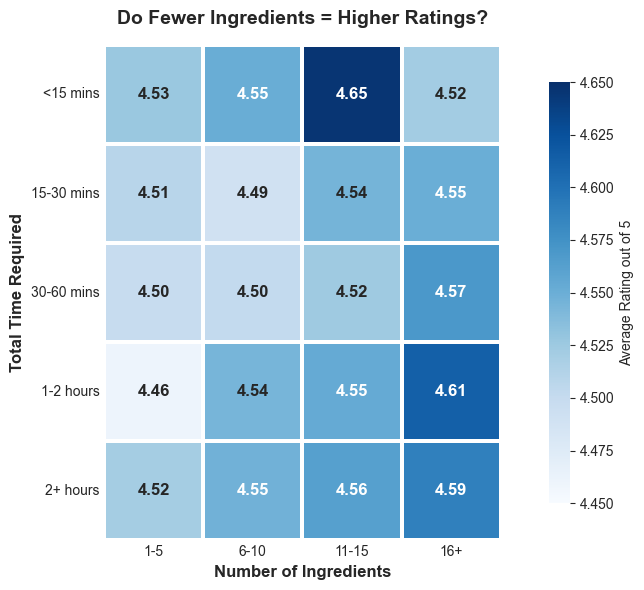

In [17]:
# Create 'total_time' and 'n_ingredient_lines' buckets
time_bins = [0, 15, 30, 60, 120, np.inf]
time_labels = ['<15 mins', '15-30 mins', '30-60 mins', '1-2 hours', '2+ hours']
df_filtered['time_bucket'] = pd.cut(df_filtered['total_time'], bins = time_bins, labels = time_labels)

ingredient_bins = [0, 5, 10, 15, np.inf]
ingredient_labels = ['1-5', '6-10', '11-15', '16+']
df_filtered['ingredient_bucket'] = pd.cut(df_filtered['n_ingredient_lines'], bins = ingredient_bins, labels = ingredient_labels)

heatmap_data = df_filtered.pivot_table(
    index = 'time_bucket',
    columns = 'ingredient_bucket',
    values = 'avg_rating',
    aggfunc = 'mean'
)

# Plot the Heatmap
plt.figure(figsize = (10, 6))
sns.heatmap(
    heatmap_data,
    annot = True,
    fmt = ".2f",            # 2 decimal places
    cmap = "Blues",         # Darker blue = higher rating
    vmin = 4.45,            
    vmax = 4.65,            
    square = True,          
    linewidths = 1.5,       
    linecolor = 'white',
    annot_kws = {"size": 12, "weight": "bold"},
    cbar_kws = {'label': 'Average Rating out of 5', 'shrink': 0.85}
)
plt.title("Do Fewer Ingredients = Higher Ratings?", fontsize = 14, fontweight = 'bold', pad = 15)
plt.xlabel("Number of Ingredients", fontsize = 12, fontweight = 'bold')
plt.ylabel("Total Time Required", fontsize = 12, fontweight = 'bold')
plt.yticks(rotation = 0)
plt.tick_params(axis = 'both', which = 'both', length = 0)
plt.tight_layout()
plt.show()

## 4. Discussions

The scatterplot directly addresses our question of which recipes are most actionable by visualising the relationship between total cooking time (on a log scale) and average user rating across three serving size groups, which are small (1–4), medium (5–8), and large (9+). The upper-left quadrant, where recipes have both high ratings and low total time, is visibly the densest region across all three panels, suggesting that shorter total time is associated with higher user ratings on Allrecipes and therefore that quicker recipes tend to be the most actionable. This pattern likely reflects the nature of the platform's user base, where home cooks who attempt quicker recipes are more likely to complete them successfully and leave positive reviews, whereas longer, more complex recipes introduce more opportunities for error and disappointment. The orange star, representing the overall median recipe across the dataset, sits across all three panels as a reference point for comparison. Comparing across serving size groups, the Large (9+) panel extends further right along the x-axis relative to the star, suggesting that larger-batch recipes tend to require more time than the typical recipe, which is intuitive given the greater quantities involved. However, highly-rated recipes still exist across all time ranges in the Large panel, indicating that larger-batch recipes can still be actionable despite taking longer. Nonetheless, more notably, the Small (1–4) panel shows the densest concentration of recipes in the upper-left quadrant relative to the star, suggesting that small-serving recipes represent the most reliably actionable category.

This heatmap visualises the intersection of effort (Total Time) and complexity (Number of Ingredients) to test the hypothesis that simple, fast recipes are the most "actionable" and highly rated. 

Interestingly, the data contradicts this assumption. While fast recipes generally perform well, simplicity (1-5 ingredients) yields the lowest ratings across almost all time brackets, with the lowest being 4.46 for 1-2 hour recipes. Instead, the platform rewards flavour complexity. The highest-rated recipes involve 11-15 or 16+ ingredients, regardless of how long they take to cook. 

The "actionable" sweet spot is found in the top-right quadrant (under 15 minutes, 11-15 ingredients, peaking at 4.63), suggesting that home cooks highly value quick-assembly dishes that do not compromise on complex, ingredient-dense flavour profiles.

## 5. Teamwork
*(Tasks allocation paragraph goes here.)*

## 6. References
* TidyTuesday AllRecipes Dataset: https://github.com/rfordatascience/tidytuesday/blob/main/data/2025/2025-09-16/readme.md
* Mubia, B. (2025, September 16). Allrecipes [Data set]. TidyTuesday. https://github.com/rfordatascience/tidytuesday/blob/main/data/2025/2025-09-16/readme.md